# Random Forest Machine Learning Project — Car Evaluation

**Task:** Multiclass classification  
**Algorithm:** Random Forest Classifier  
**Target:** `class` (unacc, acc, good, vgood)

**Dataset:** `car_evaluation.csv` link:http://archive.ics.uci.edu/dataset/19/car+evaluation 

## 1. Project objective

Build an end-to-end machine learning model that predicts a car's acceptability category from its buying price, maintenance cost, number of doors, passenger capacity, luggage boot size, and safety rating.

This notebook covers data loading, exploration, missing-value handling, categorical encoding, train-test splitting, model training, evaluation, feature-importance interpretation, cross-validation, optional hyperparameter tuning, and model saving.

## 2. Dataset notes


| Feature | Meaning |
|---|---|
| `buying` | Buying price |
| `maint` | Maintenance cost |
| `doors` | Number of doors |
| `persons` | Passenger capacity |
| `lug_boot` | Luggage boot size |
| `safety` | Safety level |
| `class` | Car evaluation category (target) |

The preprocessing is placed inside a scikit-learn pipeline. This ensures that imputation and one-hot encoding are fitted on the training data only, avoiding data leakage.

## 3. Import required libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Load the dataset

In [2]:
DATA_PATH = Path("car_evaluation.csv")
column_names = [
    "buying", "maint", "doors", "persons", "lug_boot", "safety", "class"
]

df = pd.read_csv(DATA_PATH, header=None, names=column_names)

print(f"Dataset loaded from: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Dataset loaded from: E:\Unlox\Minor Project 4\car_evaluation.csv
Rows: 1,728 | Columns: 7


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## 5. Basic data exploration

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nDataset information:")
df.info()

print("\nDescriptive summary (categorical columns):")
display(df.describe(include="all").T)

print("\nUnique values in each column:")
for column in df.columns:
    print(f"{column}: {sorted(df[column].dropna().astype(str).unique().tolist())}")

print("\nTarget class counts:")
display(df["class"].value_counts().to_frame("count"))

print("\nTarget class proportions:")
display((df["class"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

Dataset shape: (1728, 7)

Column names:
['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

Data types:


,dtype
buying,object
maint,object
doors,object
persons,object
lug_boot,object
safety,object
class,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB

Descriptive summary (categorical columns):


,count,unique,top,freq
buying,1728,4,vhigh,432
maint,1728,4,vhigh,432
doors,1728,4,2,432
persons,1728,3,2,576
lug_boot,1728,3,small,576
safety,1728,3,low,576
class,1728,4,unacc,1210



Unique values in each column:
buying: ['high', 'low', 'med', 'vhigh']
maint: ['high', 'low', 'med', 'vhigh']
doors: ['2', '3', '4', '5more']
persons: ['2', '4', 'more']
lug_boot: ['big', 'med', 'small']
safety: ['high', 'low', 'med']
class: ['acc', 'good', 'unacc', 'vgood']

Target class counts:


,count
class,
unacc,1210
acc,384
good,69
vgood,65



Target class proportions:


,percentage
class,
unacc,70.02
acc,22.22
good,3.99
vgood,3.76


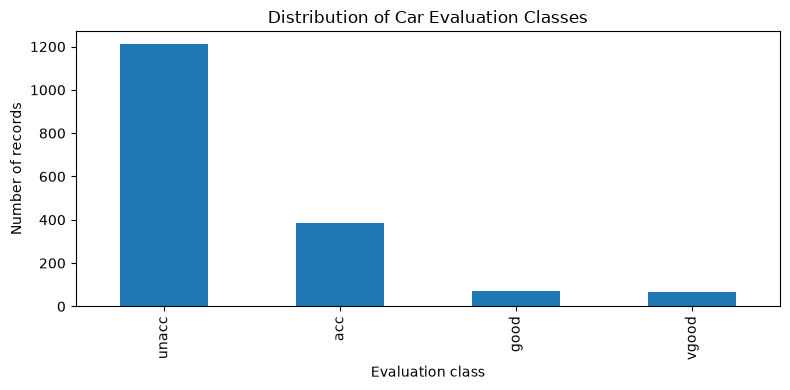

In [4]:
# Visualize the target class distribution.
plt.figure(figsize=(8, 4))
class_order = ["unacc", "acc", "good", "vgood"]
df["class"].value_counts().reindex(class_order).plot(kind="bar")
plt.title("Distribution of Car Evaluation Classes")
plt.xlabel("Evaluation class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 6. Check and handle missing values

The original Car Evaluation dataset is commonly distributed without missing values, but this notebook checks the supplied file rather than assuming that. Any missing categorical values are handled with the most-frequent-value imputer inside the preprocessing pipeline.

In [5]:
missing_counts = df.isna().sum()
missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": (missing_counts / len(df) * 100).round(2)
})
display(missing_summary)

if missing_counts.sum() == 0:
    print("No missing values found in the supplied dataset.")
else:
    print(f"Found {missing_counts.sum()} missing value(s). They will be imputed during preprocessing.")

,missing_count,missing_percent
buying,0,0.0
maint,0,0.0
doors,0,0.0
persons,0,0.0
lug_boot,0,0.0
safety,0,0.0
class,0,0.0


No missing values found in the supplied dataset.


## 7. Encode categorical variables and split features/target

All six predictors are categorical. `OneHotEncoder` converts their categories into numeric indicator columns. The target labels are kept as strings because scikit-learn classifiers can learn and predict string class labels directly.

`SimpleImputer(strategy="most_frequent")` is included before encoding so the pipeline can also handle missing values in future data.

In [6]:
X = df.drop(columns="class")
y = df["class"]

categorical_features = X.columns.tolist()

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_preprocessor, categorical_features)
    ],
    remainder="drop"
)

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
print("\nTarget labels:", sorted(y.unique()))

Features (X) shape: (1728, 6)
Target (y) shape: (1728,)

Target labels: ['acc', 'good', 'unacc', 'vgood']


## 8. Perform Train-Test Split

A stratified split preserves approximately the same class proportions in the training and test sets. The test set is held out for the final evaluation.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

split_summary = pd.DataFrame({
    "full_dataset_%": (y.value_counts(normalize=True) * 100),
    "training_%": (y_train.value_counts(normalize=True) * 100),
    "testing_%": (y_test.value_counts(normalize=True) * 100)
}).fillna(0).round(2)

display(split_summary)

Training feature shape: (1382, 6)
Testing feature shape: (346, 6)


,full_dataset_%,training_%,testing_%
class,,,
unacc,70.02,70.04,69.94
acc,22.22,22.21,22.25
good,3.99,3.98,4.05
vgood,3.76,3.76,3.76


## 9. Apply and train the Random Forest model

A Random Forest combines predictions from many decision trees. Each tree is trained on a bootstrap sample and considers a randomized subset of features at each split. Aggregating the trees generally makes the model more robust than relying on one decision tree.

The baseline model uses 300 trees and a fixed random seed for reproducibility. `class_weight="balanced"` gives additional weight to less frequent classes during training.

In [8]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ))
])

print(rf_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['buying', 'maint', 'doors',
                                                   'persons', 'lug_boot',
                                                   'safety'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])


## 10. Cross-validation (bonus)

Five-fold stratified cross-validation is performed on the training data only. This gives a more stable estimate of model performance while keeping the test set untouched.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision_weighted": "precision_weighted",
        "recall_weighted": "recall_weighted",
        "f1_weighted": "f1_weighted"
    },
    n_jobs=-1,
    return_train_score=False
)

cv_summary = pd.DataFrame({
    metric.replace("test_", ""): [
        cv_results[metric].mean(),
        cv_results[metric].std()
    ]
    for metric in cv_results if metric.startswith("test_")
}, index=["mean", "std"]).T

display(cv_summary.round(4))

,mean,std
accuracy,0.9580,0.0067
precision_weighted,0.9631,0.0046
recall_weighted,0.9580,0.0067
f1_weighted,0.9589,0.0067


## 11. Hyperparameter tuning (bonus)

Set `RUN_HYPERPARAMETER_TUNING = True` to run a small grid search. The default is `False` so that the notebook runs faster. The search uses only the training data and selects the model with the highest weighted F1 score under three-fold stratified cross-validation.

In [10]:
RUN_HYPERPARAMETER_TUNING = False  # Change to True to enable GridSearchCV

if RUN_HYPERPARAMETER_TUNING:
    param_grid = {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [None, 15],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [1, 2]
    }

    grid_search = GridSearchCV(
        estimator=rf_pipeline,
        param_grid=param_grid,
        scoring="f1_weighted",
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1,
        verbose=1
    )
    grid_search.fit(X_train, y_train)

    final_model = grid_search.best_estimator_
    print("Best parameters:", grid_search.best_params_)
    print(f"Best cross-validation weighted F1: {grid_search.best_score_:.4f}")
else:
    final_model = rf_pipeline
    print("Hyperparameter tuning skipped. Using the baseline Random Forest.")

Hyperparameter tuning skipped. Using the baseline Random Forest.


## 12. Train the final model and make predictions

In [11]:
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

print("Final model trained successfully.")
print("First 10 predictions:", y_pred[:10])

Final model trained successfully.
First 10 predictions: ['good' 'unacc' 'unacc' 'unacc' 'acc' 'unacc' 'unacc' 'acc' 'unacc'
 'unacc']


## 13. Model evaluation

The problem is multiclass classification. Accuracy is reported along with **weighted** precision, recall, and F1-score so that each class contributes according to its number of true examples. The confusion matrix shows the counts of correct and incorrect predictions for every class.

In [12]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)"],
    "Score": [accuracy, precision, recall, f1]
})
display(metrics_df.style.format({"Score": "{:.4f}"}))

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

,Metric,Score
0,Accuracy,0.9711
1,Precision (weighted),0.9732
2,Recall (weighted),0.9711
3,F1-score (weighted),0.9715



Detailed classification report:
              precision    recall  f1-score   support

         acc       0.90      0.97      0.94        77
        good       0.93      1.00      0.97        14
       unacc       1.00      0.97      0.98       242
       vgood       0.93      1.00      0.96        13

    accuracy                           0.97       346
   macro avg       0.94      0.99      0.96       346
weighted avg       0.97      0.97      0.97       346



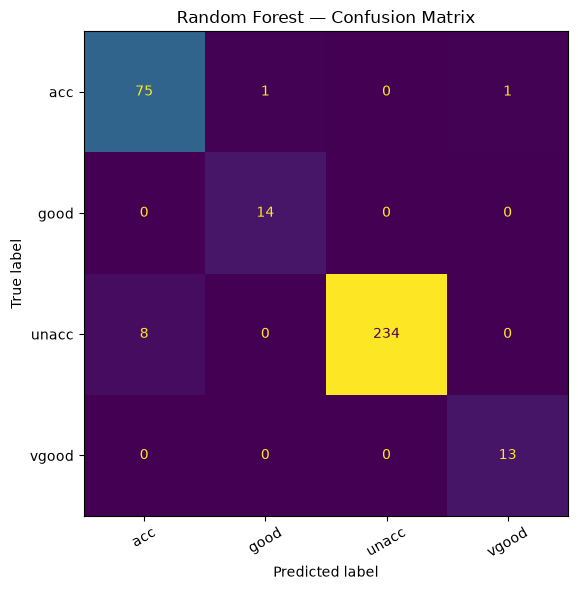

In [13]:
labels = final_model.named_steps["classifier"].classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax, values_format="d", colorbar=False
)
plt.title("Random Forest — Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 14. Explain and visualize feature importance

Random Forest feature importance measures the total reduction in impurity contributed by each encoded feature across the trees. Since one-hot encoding expands each original feature into several indicator columns, the plot below shows the encoded feature names.



,feature,importance
0,categorical__persons_2,0.0996
1,categorical__safety_high,0.0870
2,categorical__safety_low,0.0836
3,categorical__lug_boot_small,0.0784
4,categorical__safety_med,0.0713
5,categorical__buying_low,0.0566
6,categorical__buying_high,0.0553
7,categorical__maint_vhigh,0.0547
8,categorical__lug_boot_big,0.0521
9,categorical__buying_vhigh,0.0511


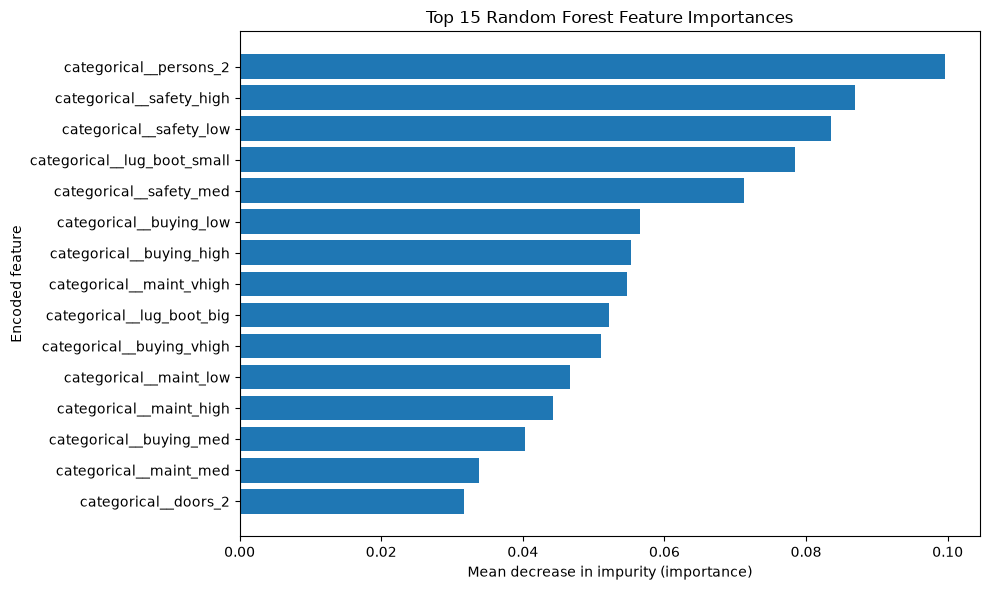

In [14]:
fitted_preprocessor = final_model.named_steps["preprocessor"]
rf_classifier = final_model.named_steps["classifier"]

encoded_feature_names = fitted_preprocessor.get_feature_names_out()
importance_values = rf_classifier.feature_importances_

feature_importance = (
    pd.DataFrame({
        "feature": encoded_feature_names,
        "importance": importance_values
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.head(15).style.format({"importance": "{:.4f}"}))

top_n = min(15, len(feature_importance))
plot_data = feature_importance.head(top_n).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(plot_data["feature"], plot_data["importance"])
plt.title(f"Top {top_n} Random Forest Feature Importances")
plt.xlabel("Mean decrease in impurity (importance)")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

## 15. Example prediction on a new car

In [15]:
# Example values use the categories present in the Car Evaluation dataset.
new_car = pd.DataFrame([{
    "buying": "vhigh",
    "maint": "high",
    "doors": "4",
    "persons": "more",
    "lug_boot": "big",
    "safety": "high"
}])

predicted_class = final_model.predict(new_car)[0]
print("Example car details:")
display(new_car)
print("Predicted evaluation class:", predicted_class)

# Optional class probabilities
if hasattr(final_model.named_steps["classifier"], "predict_proba"):
    probabilities = final_model.predict_proba(new_car)[0]
    probability_table = pd.DataFrame({
        "class": final_model.named_steps["classifier"].classes_,
        "predicted_probability": probabilities
    }).sort_values("predicted_probability", ascending=False)
    display(probability_table.style.format({"predicted_probability": "{:.4f}"}))

Example car details:


,buying,maint,doors,persons,lug_boot,safety
0,vhigh,high,4,more,big,high


Predicted evaluation class: unacc


,class,predicted_probability
2,unacc,0.8233
0,acc,0.1667
3,vgood,0.0100
1,good,0.0000


## 16. Save the trained model (bonus)

In [16]:
MODEL_PATH = Path("random_forest_car_evaluation.joblib")
joblib.dump(final_model, MODEL_PATH)
print(f"Model saved to: {MODEL_PATH.resolve()}")

# Demonstrate loading the saved model and making a prediction.
loaded_model = joblib.load(MODEL_PATH)
loaded_prediction = loaded_model.predict(new_car)[0]
print("Prediction from the loaded model:", loaded_prediction)

Model saved to: E:\Unlox\Minor Project 4\random_forest_car_evaluation.joblib
Prediction from the loaded model: unacc


## 17. Conclusion

In [17]:
top_features = feature_importance.head(5)["feature"].tolist()

print("PROJECT CONCLUSION")
print("------------------")
print(f"The Random Forest model achieved {accuracy:.2%} accuracy on the held-out test set.")
print(f"Weighted precision: {precision:.2%}")
print(f"Weighted recall:    {recall:.2%}")
print(f"Weighted F1-score:  {f1:.2%}")

print("\nThe five most important encoded features for this fitted model were:")
for rank, feature in enumerate(top_features, start=1):
    print(f"{rank}. {feature}")

print(
    "\nThese results show how well the model predicts the four car-evaluation classes "
    "on this particular test split. Feature importance highlights which encoded "
    "attributes contributed most to the forest's decisions, but it does not establish "
    "causal relationships."
)

print(
    "\nFor future improvement, we can compare the baseline with the optional tuned model, "
    "inspect class-wise precision and recall, and validate performance on additional "
    "unseen data."
)

PROJECT CONCLUSION
------------------
The Random Forest model achieved 97.11% accuracy on the held-out test set.
Weighted precision: 97.32%
Weighted recall:    97.11%
Weighted F1-score:  97.15%

The five most important encoded features for this fitted model were:
1. categorical__persons_2
2. categorical__safety_high
3. categorical__safety_low
4. categorical__lug_boot_small
5. categorical__safety_med

These results show how well the model predicts the four car-evaluation classes on this particular test split. Feature importance highlights which encoded attributes contributed most to the forest's decisions, but it does not establish causal relationships.

For future improvement, we can compare the baseline with the optional tuned model, inspect class-wise precision and recall, and validate performance on additional unseen data.


## 18. Key learning outcomes

- Loaded and explored a real-world categorical dataset.
- Checked missing values and handled them inside a preprocessing pipeline.
- Converted categorical predictors using one-hot encoding.
- Split data into stratified training and testing sets.
- Trained a Random Forest classifier.
- Evaluated multiclass predictions using accuracy, weighted precision, weighted recall, weighted F1-score, a classification report, and a confusion matrix.
- Used cross-validation and provided optional GridSearchCV hyperparameter tuning.
- Interpreted and visualized feature importance.
- Saved and reloaded the trained model with Joblib.

